In [ ]:
!pip -q install nltk gensim scikit-learn tensorflow

import os, re, html, random, time
import numpy as np
import pandas as pd

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Dense, Dropout, Embedding, SimpleRNN, GRU, LSTM,
    Bidirectional, GlobalAveragePooling1D, Input
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

from gensim.models import Word2Vec

import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 93.6 MB/s eta 0:00:00


In [ ]:

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
BASE_PATH = "/content/drive/MyDrive/CSE440_Project/"

TRAIN_PATH = BASE_PATH + "Question Answer Classification Dataset 6(1).csv"
TEST_PATH  = BASE_PATH + "[Updated] Question Answer Classification Dataset[Test].csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df  = pd.read_csv(TEST_PATH)

assert "QA Text" in train_df.columns and "Class" in train_df.columns, "Train CSV must have columns: 'QA Text', 'Class'"
assert "QA Text" in test_df.columns and "Class" in test_df.columns, "Test CSV must have columns: 'QA Text', 'Class'"

train_df["QA Text"] = train_df["QA Text"].astype(str)
test_df["QA Text"]  = test_df["QA Text"].astype(str)

train_df["Class"] = train_df["Class"].astype(str)
test_df["Class"]  = test_df["Class"].astype(str)

## 1) Exploratory Data Analysis (EDA)

Covers missing values, class distribution, text length distribution, and frequent-word inspection (raw + cleaned).

In [ ]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain missing values:\n", train_df[["QA Text","Class"]].isna().sum())
print("\nTest missing values:\n", test_df[["QA Text","Class"]].isna().sum())

Train shape: (93333, 2)
Test shape: (59999, 2)

Train missing values:
 QA Text    0
Class      0
dtype: int64

Test missing values:
 QA Text    0
Class      0
dtype: int64


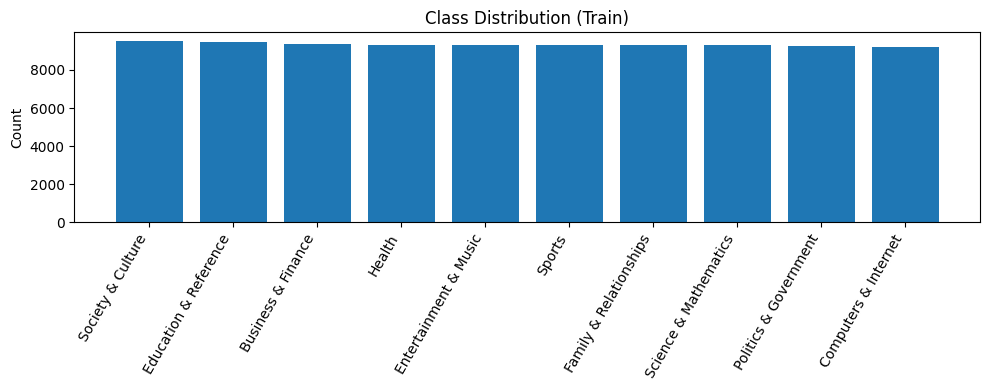

,count
Class,
Society & Culture,9502
Education & Reference,9474
Business & Finance,9379
Health,9310
Entertainment & Music,9306
Sports,9304
Family & Relationships,9296
Science & Mathematics,9288
Politics & Government,9258


In [ ]:

class_counts = train_df["Class"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Count")
plt.title("Class Distribution (Train)")
plt.tight_layout()
plt.show()

class_counts.to_frame(name="count")

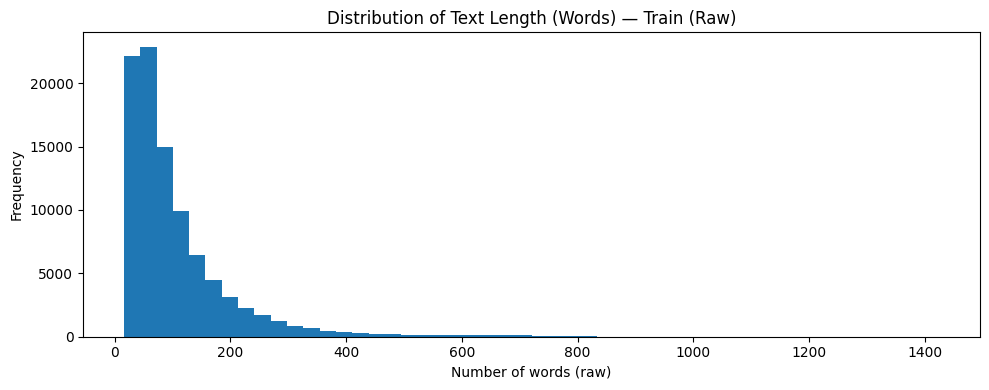

,len_chars_raw,len_words_raw
count,93333.000000,93333.000000
mean,634.593434,106.480441
std,578.772310,98.879051
min,127.000000,16.000000
25%,289.000000,46.000000
50%,452.000000,75.000000
75%,753.000000,129.000000
max,7995.000000,1425.000000


In [ ]:

train_df["len_chars_raw"] = train_df["QA Text"].apply(len)
train_df["len_words_raw"] = train_df["QA Text"].apply(lambda s: len(str(s).split()))

plt.figure(figsize=(10, 4))
plt.hist(train_df["len_words_raw"], bins=50)
plt.xlabel("Number of words (raw)")
plt.ylabel("Frequency")
plt.title("Distribution of Text Length (Words) — Train (Raw)")
plt.tight_layout()
plt.show()

train_df[["len_chars_raw","len_words_raw"]].describe()

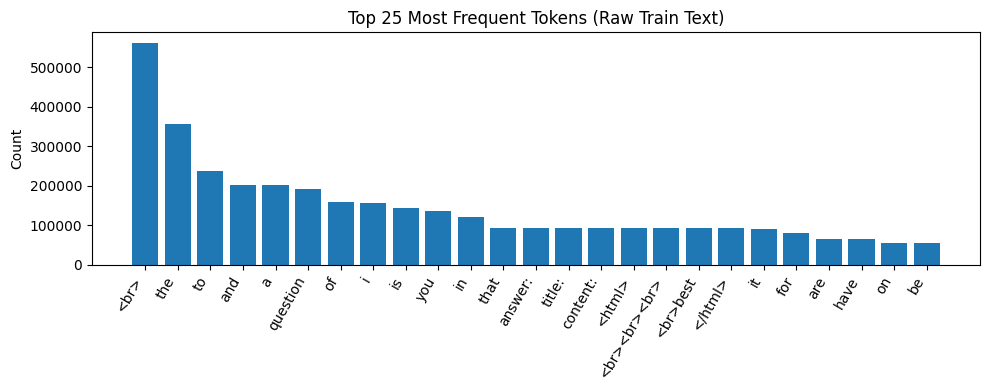

,token,count
0,<br>,559999
1,the,355575
2,to,236438
3,and,201054
4,a,200774
5,question,191375
6,of,159845
7,i,157205
8,is,144201
9,you,137419


In [ ]:

def top_words(texts, topn=25):
    tokens = []
    for s in texts:
        tokens.extend(str(s).lower().split())
    c = Counter(tokens)
    return c.most_common(topn)

top_raw = top_words(train_df["QA Text"].values, topn=25)
words, counts = zip(*top_raw)

plt.figure(figsize=(10, 4))
plt.bar(words, counts)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Count")
plt.title("Top 25 Most Frequent Tokens (Raw Train Text)")
plt.tight_layout()
plt.show()

pd.DataFrame(top_raw, columns=["token","count"])

## 2) Preprocessing

Dataset-aware cleaning: removes header markers (`Question Title`, `Question Body`, `Answer`), HTML/URLs, keeps digits, stopwords removal, and lemmatization (verb + noun).

In [ ]:
STOP_WORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

HEADER_PATTERNS = [
    r"question\s*title\s*:",
    r"question\s*body\s*:",
    r"answer\s*:"
]

def clean_text(s: str) -> str:
    s = str(s)
    s = html.unescape(s)


    for pat in HEADER_PATTERNS:
        s = re.sub(pat, " ", s, flags=re.IGNORECASE)


    s = re.sub(r"<.*?>", " ", s)
    s = re.sub(r"http\S+|www\S+", " ", s)


    s = re.sub(r"[^a-zA-Z0-9\s]", " ", s)

    s = s.lower()
    tokens = [t for t in s.split() if t not in STOP_WORDS and len(t) > 1]


    tokens = [lemmatizer.lemmatize(t, pos="v") for t in tokens]
    tokens = [lemmatizer.lemmatize(t, pos="n") for t in tokens]

    return " ".join(tokens)

train_df["clean_text"] = train_df["QA Text"].apply(clean_text)
test_df["clean_text"]  = test_df["QA Text"].apply(clean_text)

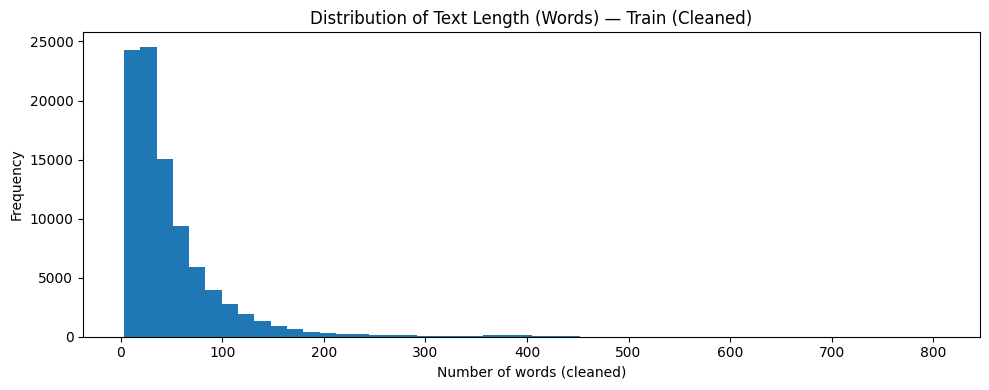

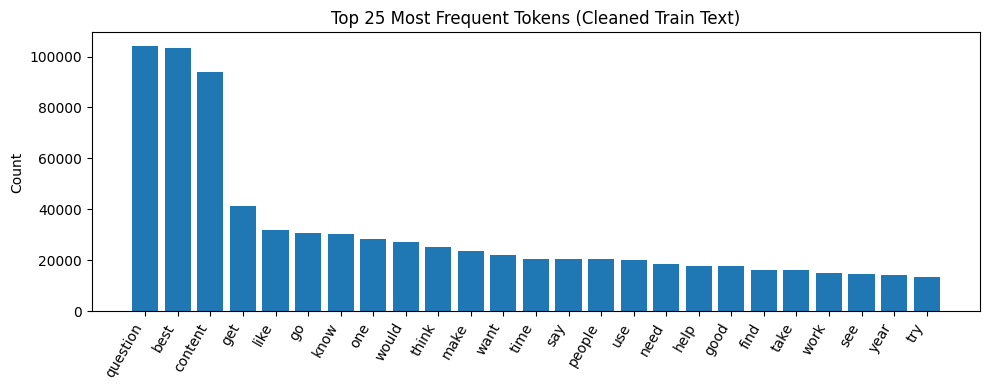

,token,count
0,question,104270
1,best,103508
2,content,93970
3,get,41500
4,like,32039
5,go,30877
6,know,30527
7,one,28224
8,would,27392
9,think,25191


In [ ]:

train_df["len_words_clean"] = train_df["clean_text"].apply(lambda s: len(str(s).split()))

plt.figure(figsize=(10, 4))
plt.hist(train_df["len_words_clean"], bins=50)
plt.xlabel("Number of words (cleaned)")
plt.ylabel("Frequency")
plt.title("Distribution of Text Length (Words) — Train (Cleaned)")
plt.tight_layout()
plt.show()

top_clean = top_words(train_df["clean_text"].values, topn=25)
words, counts = zip(*top_clean)

plt.figure(figsize=(10, 4))
plt.bar(words, counts)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Count")
plt.title("Top 25 Most Frequent Tokens (Cleaned Train Text)")
plt.tight_layout()
plt.show()

pd.DataFrame(top_clean, columns=["token","count"])

## 3) Train/Validation/Test setup

Split training data into train/validation for tuning; use provided test set only for final evaluation.

In [ ]:
le = LabelEncoder()
y_train_all_int = le.fit_transform(train_df["Class"])
y_test_int      = le.transform(test_df["Class"])

num_classes = len(le.classes_)
y_train_all_oh = tf.keras.utils.to_categorical(y_train_all_int, num_classes=num_classes)

X_tr_text, X_val_text, y_tr_int, y_val_int, y_tr_oh, y_val_oh = train_test_split(
    train_df["clean_text"].values,
    y_train_all_int,
    y_train_all_oh,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train_all_int
)

print("Train-sub size:", len(X_tr_text), "Validation size:", len(X_val_text), "Test size:", len(test_df))

Train-sub size: 83999 Validation size: 9334 Test size: 59999


In [ ]:
def macro_f1(y_true_int, y_pred_int):
    return float(f1_score(y_true_int, y_pred_int, average="macro"))

def eval_metrics(y_true_int, y_pred_int):
    return {
        "accuracy": float(accuracy_score(y_true_int, y_pred_int)),
        "macro_f1": float(f1_score(y_true_int, y_pred_int, average="macro"))
    }

def record_row(model_name, y_true_int, y_pred_int, best_cfg, best_val_f1, bestfit_seconds, search_seconds):
    m = eval_metrics(y_true_int, y_pred_int)
    return {
        "model": model_name,
        "accuracy": m["accuracy"],
        "macro_f1": m["macro_f1"],
        "best_val_macro_f1": float(best_val_f1),
        "best_cfg": best_cfg,
        "train_seconds_bestfit": float(bestfit_seconds),
        "search_seconds_total": float(search_seconds),
    }

## 4) TF‑IDF track (2 experiments): 1 ML model + 1 DNN

Manual tuning uses validation macro‑F1.

In [ ]:

tfidf_vectorizer = TfidfVectorizer( max_features=5000, ngram_range=(1,1),min_df=2)

X_tr_tfidf   = tfidf_vectorizer.fit_transform(X_tr_text)
X_val_tfidf  = tfidf_vectorizer.transform(X_val_text)
X_test_tfidf = tfidf_vectorizer.transform(test_df["clean_text"].values)

In [ ]:
# (1) TF-IDF + Logistic Regression
logreg_grid = [{"C": 0.1}, {"C": 1.0}, {"C": 10.0}]

best_lr = None
best_cfg_lr = None
best_val_f1_lr = -1
best_fit_seconds_lr = 0.0

t_search0 = time.time()
for cfg in logreg_grid:
    clf = LogisticRegression(C=cfg["C"], max_iter=2000, random_state=SEED)
    t0 = time.time()
    clf.fit(X_tr_tfidf, y_tr_int)
    fit_secs = time.time() - t0

    val_pred = clf.predict(X_val_tfidf)
    val_f1 = macro_f1(y_val_int, val_pred)

    if val_f1 > best_val_f1_lr:
        best_val_f1_lr = val_f1
        best_cfg_lr = cfg
        best_lr = clf
        best_fit_seconds_lr = fit_secs

search_seconds_lr = time.time() - t_search0
test_pred_lr = best_lr.predict(X_test_tfidf)

print("TFIDF+LogReg best config:", best_cfg_lr)
print("Best validation macro-F1:", best_val_f1_lr)

test_acc = accuracy_score(y_test_int, test_pred_lr)
test_f1  = f1_score(y_test_int, test_pred_lr, average="macro")
print("Test Accuracy:", test_acc)
print("Test Macro-F1:", test_f1)


TFIDF+LogReg best config: {'C': 1.0}
Best validation macro-F1: 0.677762970491902
Test Accuracy: 0.6756112601876698
Test Macro-F1: 0.6734302105240605


In [ ]:
# (2) TF-IDF + DNN
X_tr_tfidf_dense   = X_tr_tfidf.astype("float32").toarray()
X_val_tfidf_dense  = X_val_tfidf.astype("float32").toarray()
X_test_tfidf_dense = X_test_tfidf.astype("float32").toarray()

def build_tfidf_dnn(input_dim, num_classes, hidden, drop, lr):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for h in hidden:
        model.add(Dense(h, activation="relu"))
        model.add(Dropout(drop))
    model.add(Dense(num_classes, activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

tfidf_dnn_grid = [
    {"hidden": [128], "drop": 0.3, "lr": 1e-3},
    {"hidden": [256], "drop": 0.5, "lr": 1e-3},
    {"hidden": [256, 128], "drop": 0.5, "lr": 3e-4},
]

es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

best_tfidf_dnn = None
best_cfg_dnn = None
best_val_f1_dnn = -1
best_fit_seconds_dnn = 0.0

t_search0 = time.time()
for cfg in tfidf_dnn_grid:
    model = build_tfidf_dnn(X_tr_tfidf_dense.shape[1], num_classes, cfg["hidden"], cfg["drop"], cfg["lr"])
    t0 = time.time()
    model.fit(X_tr_tfidf_dense, y_tr_oh,
              validation_data=(X_val_tfidf_dense, y_val_oh),
              epochs=10, batch_size=32, callbacks=[es], verbose=0)
    fit_secs = time.time() - t0

    val_pred = np.argmax(model.predict(X_val_tfidf_dense, verbose=0), axis=1)
    val_f1 = macro_f1(y_val_int, val_pred)

    if val_f1 > best_val_f1_dnn:
        best_val_f1_dnn = val_f1
        best_cfg_dnn = cfg
        best_tfidf_dnn = model
        best_fit_seconds_dnn = fit_secs

search_seconds_dnn = time.time() - t_search0
test_pred_dnn = np.argmax(best_tfidf_dnn.predict(X_test_tfidf_dense, verbose=0), axis=1)

## 5) Skip‑gram track (7 experiments): pooled DNN + RNN/GRU/LSTM + bidirectional

Manual tuning uses validation macro‑F1; test evaluation is done once per model after selecting best hyperparameters.

In [ ]:
w2v_cfg = {"vector_size": 100, "window": 5, "min_count": 2, "sg": 1, "workers": 4, "epochs": 10}
sentences = [t.split() for t in X_tr_text]
w2v = Word2Vec(sentences=sentences, **w2v_cfg)

NUM_WORDS = 50000
tokenizer = Tokenizer(num_words=NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_tr_text.tolist())

X_tr_seq   = tokenizer.texts_to_sequences(X_tr_text.tolist())
X_val_seq  = tokenizer.texts_to_sequences(X_val_text.tolist())
X_test_seq = tokenizer.texts_to_sequences(test_df["clean_text"].values.tolist())

vocab_size = min(NUM_WORDS, len(tokenizer.word_index) + 1)
embed_dim = w2v_cfg["vector_size"]

embedding_matrix = np.zeros((vocab_size, embed_dim), dtype=np.float32)
for word, idx in tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    if word in w2v.wv:
        embedding_matrix[idx] = w2v.wv[word]

def pad_for_len(seq_list, max_len):
    return pad_sequences(seq_list, maxlen=max_len, padding="post", truncating="post")

In [ ]:
RNN_LAYER = {"rnn": SimpleRNN, "gru": GRU, "lstm": LSTM}

def build_skipgram_pooled_dnn(vocab_size, embed_dim, max_len, num_classes, embedding_matrix,
                              hidden=64, drop=0.5, lr=1e-3, trainable=False):
    model = Sequential([
        Embedding(vocab_size, embed_dim, input_length=max_len, weights=[embedding_matrix], trainable=trainable),
        GlobalAveragePooling1D(),
        Dense(hidden, activation="relu"),
        Dropout(drop),
        Dense(num_classes, activation="softmax")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

def build_rnn_model(kind, vocab_size, embed_dim, max_len, num_classes, embedding_matrix,
                    units=64, bidir=False, trainable=False, drop=0.5, lr=1e-3):
    base = RNN_LAYER[kind](units)
    rnn = Bidirectional(base) if bidir else base
    model = Sequential([
        Embedding(vocab_size, embed_dim, input_length=max_len, weights=[embedding_matrix], trainable=trainable),
        rnn,
        Dropout(drop),
        Dense(num_classes, activation="softmax")
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

In [ ]:
FAST_MODE = False

max_len_grid = [100] if FAST_MODE else [100, 200]
units_grid   = [32, 64]
drop_grid    = [0.3, 0.5]
lr_grid      = [1e-3]

EPOCHS = 15
BATCH_SIZE = 64
es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

nn_roster = [
    ("pooled_dnn", False, "SkipGram+DNN(Pooled)"),
    ("rnn", False, "SkipGram+SimpleRNN"),
    ("gru", False, "SkipGram+GRU"),
    ("lstm", False, "SkipGram+LSTM"),
    ("rnn", True,  "SkipGram+BiSimpleRNN"),
    ("gru", True,  "SkipGram+BiGRU"),
    ("lstm", True, "SkipGram+BiLSTM"),
]

best_nn_models = {}
test_predictions = {"TFIDF+LogReg": test_pred_lr, "TFIDF+DNN": test_pred_dnn}
nn_rows = []

for kind, bidir, model_name in nn_roster:
    best_model = None
    best_cfg = None
    best_val_f1 = -1
    best_fit_seconds = 0.0

    t_search0 = time.time()
    for max_len in max_len_grid:
        X_tr_pad  = pad_for_len(X_tr_seq,  max_len)
        X_val_pad = pad_for_len(X_val_seq, max_len)

        for units in units_grid:
            for drop in drop_grid:
                for lr in lr_grid:
                    cfg = {"max_len": max_len, "units": units, "drop": drop, "lr": lr, "embed_trainable": False}

                    if kind == "pooled_dnn":
                        model = build_skipgram_pooled_dnn(
                            vocab_size, embed_dim, max_len, num_classes, embedding_matrix,
                            hidden=units, drop=drop, lr=lr, trainable=False
                        )
                    else:
                        model = build_rnn_model(
                            kind, vocab_size, embed_dim, max_len, num_classes, embedding_matrix,
                            units=units, bidir=bidir, trainable=False, drop=drop, lr=lr
                        )

                    t0 = time.time()
                    model.fit(X_tr_pad, y_tr_oh,
                              validation_data=(X_val_pad, y_val_oh),
                              epochs=EPOCHS, batch_size=BATCH_SIZE,
                              callbacks=[es], verbose=0)
                    fit_secs = time.time() - t0

                    val_pred = np.argmax(model.predict(X_val_pad, verbose=0), axis=1)
                    val_f1 = macro_f1(y_val_int, val_pred)

                    if val_f1 > best_val_f1:
                        best_val_f1 = val_f1
                        best_cfg = cfg
                        best_model = model
                        best_fit_seconds = fit_secs

    search_seconds = time.time() - t_search0

    X_test_pad = pad_for_len(X_test_seq, best_cfg["max_len"])
    test_pred = np.argmax(best_model.predict(X_test_pad, verbose=0), axis=1)

    nn_rows.append(record_row(model_name, y_test_int, test_pred, best_cfg, best_val_f1, best_fit_seconds, search_seconds))
    best_nn_models[model_name] = {"model": best_model, "cfg": best_cfg, "best_val_f1": best_val_f1}
    test_predictions[model_name] = test_pred

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
/usr/local/lib/p

## 6) Consolidated Results (Tabular)

`results_df` is the main comparison table required by the instructions.

In [ ]:

rows = []
rows.append(record_row("TFIDF+LogReg", y_test_int, test_pred_lr, best_cfg_lr, best_val_f1_lr, best_fit_seconds_lr, search_seconds_lr))
rows.append(record_row("TFIDF+DNN",    y_test_int, test_pred_dnn, best_cfg_dnn, best_val_f1_dnn, best_fit_seconds_dnn, search_seconds_dnn))
rows.extend(nn_rows)

results_df = pd.DataFrame(rows).sort_values(by="macro_f1", ascending=False).reset_index(drop=True)
results_df

,model,accuracy,macro_f1,best_val_macro_f1,best_cfg,train_seconds_bestfit,search_seconds_total
0,SkipGram+BiLSTM,0.714012,0.709841,0.712901,"{'max_len': 200, 'units': 64, 'drop': 0.5, 'lr...",400.842938,2435.547306
1,SkipGram+GRU,0.712645,0.707617,0.713346,"{'max_len': 200, 'units': 64, 'drop': 0.5, 'lr...",223.554771,1643.982752
2,SkipGram+BiGRU,0.711712,0.706961,0.711089,"{'max_len': 100, 'units': 32, 'drop': 0.5, 'lr...",232.097140,1965.880592
3,SkipGram+LSTM,0.707378,0.702067,0.699107,"{'max_len': 100, 'units': 64, 'drop': 0.3, 'lr...",166.577330,963.283252
4,TFIDF+DNN,0.684295,0.679488,0.684984,"{'hidden': [128], 'drop': 0.3, 'lr': 0.001}",34.899464,122.936897
5,SkipGram+DNN(Pooled),0.683178,0.677654,0.680170,"{'max_len': 100, 'units': 64, 'drop': 0.3, 'lr...",55.848236,480.263800
6,TFIDF+LogReg,0.675611,0.673430,0.677763,{'C': 1.0},15.823938,54.675704
7,SkipGram+BiSimpleRNN,0.674945,0.669367,0.674518,"{'max_len': 200, 'units': 64, 'drop': 0.3, 'lr...",359.562831,2252.511718
8,SkipGram+SimpleRNN,0.349172,0.278029,0.279197,"{'max_len': 100, 'units': 64, 'drop': 0.5, 'lr...",106.886188,1021.912802


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def record_row(model_name, y_true, y_pred, best_cfg, best_val_f1, fit_seconds, search_seconds):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "best_val_macro_f1": best_val_f1,
        "best_cfg": best_cfg,
        "fit_seconds": fit_seconds,
        "search_seconds": search_seconds
    }


## 7) Required Metrics + Plots + Comparisons

Generates accuracy & macro‑F1 plots, confusion matrices (visual), classification reports, best/worst identification, and best ML vs best NN comparison.

In [ ]:
best_row = results_df.iloc[0].to_dict()
worst_row = results_df.iloc[-1].to_dict()

print("BEST MODEL:", best_row["model"], "| Macro F1:", best_row["macro_f1"], "| Accuracy:", best_row["accuracy"])
print("WORST MODEL:", worst_row["model"], "| Macro F1:", worst_row["macro_f1"], "| Accuracy:", worst_row["accuracy"])

BEST MODEL: SkipGram+BiLSTM | Macro F1: 0.7098412717723649 | Accuracy: 0.7140119001983366
WORST MODEL: SkipGram+SimpleRNN | Macro F1: 0.2780292457965404 | Accuracy: 0.3491724862081035


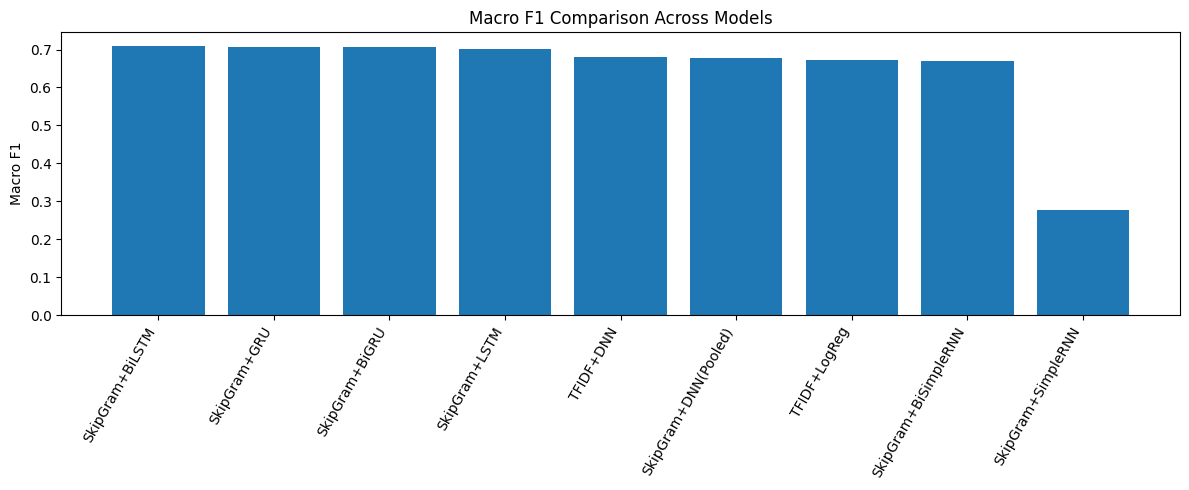

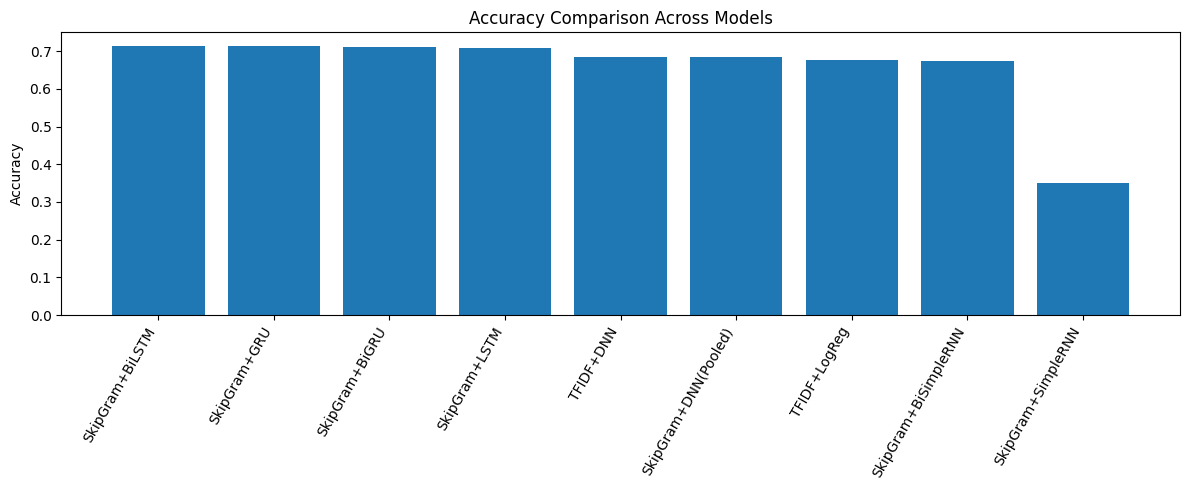

In [ ]:
# Macro-F1 bar chart
plt.figure(figsize=(12, 5))
plt.bar(results_df["model"], results_df["macro_f1"])
plt.xticks(rotation=60, ha="right")
plt.ylabel("Macro F1")
plt.title("Macro F1 Comparison Across Models")
plt.tight_layout()
plt.show()

# Accuracy bar chart
plt.figure(figsize=(12, 5))
plt.bar(results_df["model"], results_df["accuracy"])
plt.xticks(rotation=60, ha="right")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison Across Models")
plt.tight_layout()
plt.show()

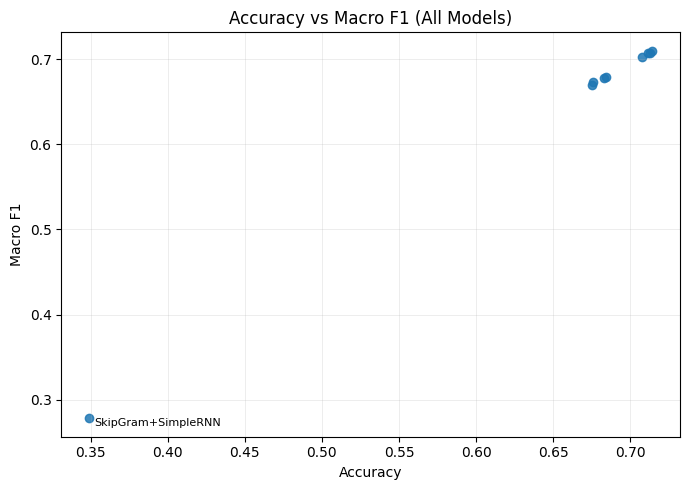

In [ ]:
# Accuracy vs Macro-F1 scatter

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

x = results_df["accuracy"].astype(float).to_numpy()
y = results_df["macro_f1"].astype(float).to_numpy()

plt.scatter(x, y, alpha=0.85)


for i, row in results_df.reset_index(drop=True).iterrows():
  dx = 0.003 * ((i % 3) - 1)
  dy = 0.006 * ((i % 4) - 1.5)
plt.annotate(
str(row["model"]),
(float(row["accuracy"]) + dx, float(row["macro_f1"]) + dy),
fontsize=8
)

plt.xlabel("Accuracy")
plt.ylabel("Macro F1")
plt.title("Accuracy vs Macro F1 (All Models)")
plt.grid(True, linewidth=0.4, alpha=0.4)
plt.tight_layout()
plt.show()


=== CLASSIFICATION REPORT: BEST MODEL ===
SkipGram+BiLSTM
                        precision    recall  f1-score   support

    Business & Finance       0.59      0.52      0.55      6000
  Computers & Internet       0.83      0.87      0.85      6000
 Education & Reference       0.59      0.48      0.53      6000
 Entertainment & Music       0.73      0.66      0.69      6000
Family & Relationships       0.68      0.80      0.74      5999
                Health       0.73      0.83      0.78      6000
 Politics & Government       0.76      0.78      0.77      6000
 Science & Mathematics       0.72      0.75      0.73      6000
     Society & Culture       0.62      0.57      0.59      6000
                Sports       0.86      0.87      0.86      6000

              accuracy                           0.71     59999
             macro avg       0.71      0.71      0.71     59999
          weighted avg       0.71      0.71      0.71     59999



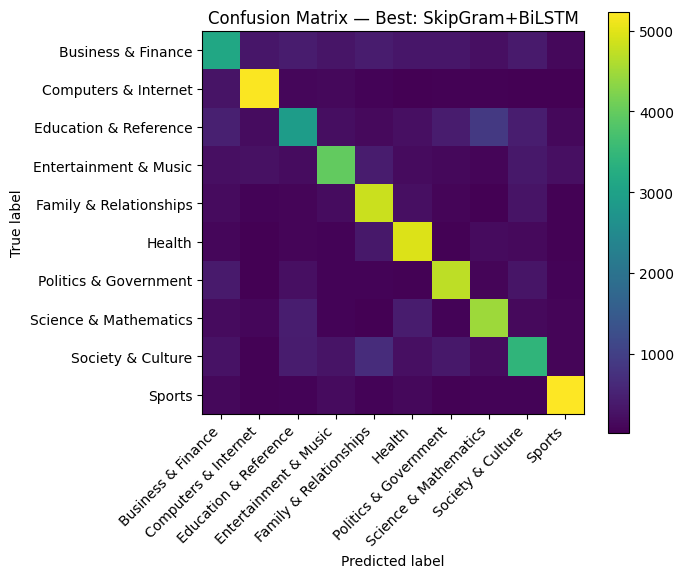


=== CLASSIFICATION REPORT: WORST MODEL ===
SkipGram+SimpleRNN
                        precision    recall  f1-score   support

    Business & Finance       0.29      0.00      0.01      6000
  Computers & Internet       0.62      0.77      0.69      6000
 Education & Reference       0.15      0.00      0.00      6000
 Entertainment & Music       0.38      0.25      0.30      6000
Family & Relationships       0.31      0.66      0.42      5999
                Health       0.20      0.50      0.29      6000
 Politics & Government       0.52      0.04      0.07      6000
 Science & Mathematics       0.26      0.59      0.36      6000
     Society & Culture       0.40      0.01      0.02      6000
                Sports       0.58      0.66      0.62      6000

              accuracy                           0.35     59999
             macro avg       0.37      0.35      0.28     59999
          weighted avg       0.37      0.35      0.28     59999



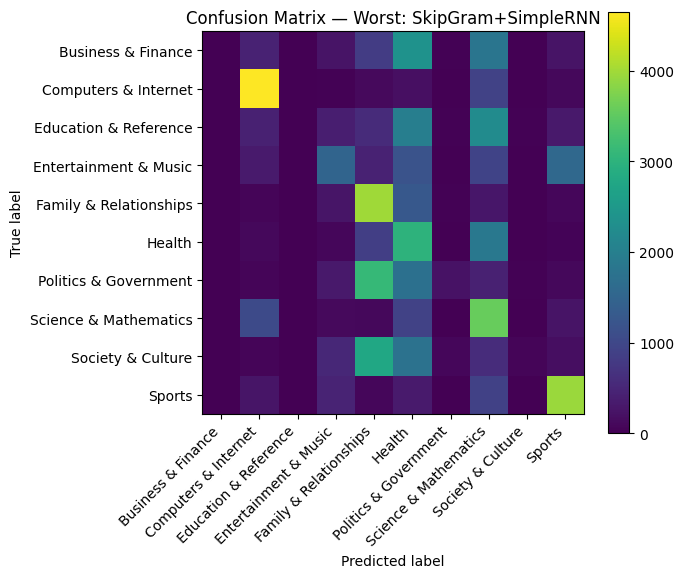

In [ ]:
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(7, 6))
    plt.imshow(cm, interpolation="nearest")
    plt.title(title)
    plt.colorbar()
    ticks = np.arange(len(le.classes_))
    plt.xticks(ticks, le.classes_, rotation=45, ha="right")
    plt.yticks(ticks, le.classes_)
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.show()

best_pred = test_predictions[best_row["model"]]
worst_pred = test_predictions[worst_row["model"]]

best_cm = confusion_matrix(y_test_int, best_pred)
worst_cm = confusion_matrix(y_test_int, worst_pred)

print("\n=== CLASSIFICATION REPORT: BEST MODEL ===")
print(best_row["model"])
print(classification_report(y_test_int, best_pred, target_names=le.classes_))
plot_confusion_matrix(best_cm, f"Confusion Matrix — Best: {best_row['model']}")

print("\n=== CLASSIFICATION REPORT: WORST MODEL ===")
print(worst_row["model"])
print(classification_report(y_test_int, worst_pred, target_names=le.classes_))
plot_confusion_matrix(worst_cm, f"Confusion Matrix — Worst: {worst_row['model']}")

In [ ]:
# classification report for every model
for model_name in results_df["model"]:
    print("\n" + "="*70)
    print("MODEL:", model_name)
    pred = test_predictions[model_name]
    print(classification_report(y_test_int, pred, target_names=le.classes_))


MODEL: SkipGram+BiLSTM
                        precision    recall  f1-score   support

    Business & Finance       0.59      0.52      0.55      6000
  Computers & Internet       0.83      0.87      0.85      6000
 Education & Reference       0.59      0.48      0.53      6000
 Entertainment & Music       0.73      0.66      0.69      6000
Family & Relationships       0.68      0.80      0.74      5999
                Health       0.73      0.83      0.78      6000
 Politics & Government       0.76      0.78      0.77      6000
 Science & Mathematics       0.72      0.75      0.73      6000
     Society & Culture       0.62      0.57      0.59      6000
                Sports       0.86      0.87      0.86      6000

              accuracy                           0.71     59999
             macro avg       0.71      0.71      0.71     59999
          weighted avg       0.71      0.71      0.71     59999


MODEL: SkipGram+GRU
                        precision    recall  f1-score   

In [ ]:
# Best ML vs Best NN comparison
best_ml = results_df[results_df["model"].str.startswith("TFIDF")].sort_values(by="macro_f1", ascending=False).iloc[0]
best_nn = results_df[results_df["model"].str.startswith("SkipGram")].sort_values(by="macro_f1", ascending=False).iloc[0]

comparison_df = pd.DataFrame([
    {"Category": "Best ML (TF-IDF)", "Model": best_ml["model"], "Accuracy": best_ml["accuracy"], "Macro F1": best_ml["macro_f1"], "Best Val Macro F1": best_ml["best_val_macro_f1"], "Best CFG": best_ml["best_cfg"]},
    {"Category": "Best NN (Skip-gram)", "Model": best_nn["model"], "Accuracy": best_nn["accuracy"], "Macro F1": best_nn["macro_f1"], "Best Val Macro F1": best_nn["best_val_macro_f1"], "Best CFG": best_nn["best_cfg"]},
])

comparison_df

,Category,Model,Accuracy,Macro F1,Best Val Macro F1,Best CFG
0,Best ML (TF-IDF),TFIDF+DNN,0.684295,0.679488,0.684984,"{'hidden': [128], 'drop': 0.3, 'lr': 0.001}"
1,Best NN (Skip-gram),SkipGram+BiLSTM,0.714012,0.709841,0.712901,"{'max_len': 200, 'units': 64, 'drop': 0.5, 'lr..."


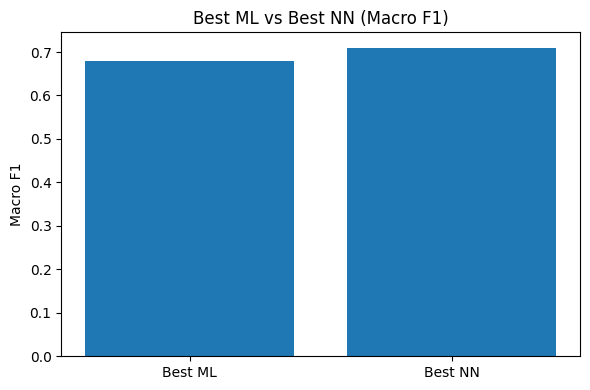

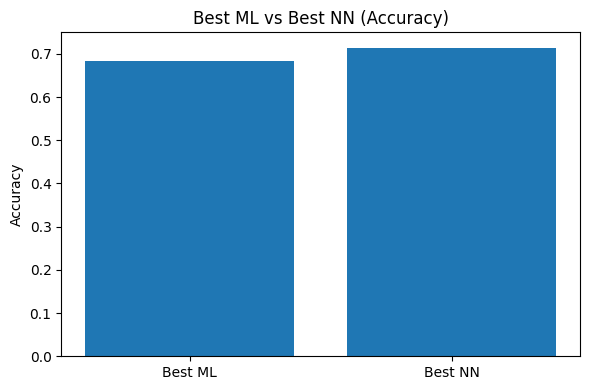

In [ ]:
# Visual: Best ML vs Best NN
plt.figure(figsize=(6, 4))
plt.bar(["Best ML", "Best NN"], [best_ml["macro_f1"], best_nn["macro_f1"]])
plt.ylabel("Macro F1")
plt.title("Best ML vs Best NN (Macro F1)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(["Best ML", "Best NN"], [best_ml["accuracy"], best_nn["accuracy"]])
plt.ylabel("Accuracy")
plt.title("Best ML vs Best NN (Accuracy)")
plt.tight_layout()
plt.show()